# Gesture-Controlled Photo Booth: Group Hyperparameter Comparison and Final Model
**IAT 360 Computer Vision Project, Group 6** (Ben Nichiporik, Daffodil Ho, Joseph Lee, Thu Nguyen)

Each member changed **one** hyperparameter of the baseline to three other values. This notebook compares all 12 tuned models with the baseline on the same data, picks the best value of each hyperparameter, tests a combination of the winners, and chooses the final model.

| Member | Hyperparameter | Baseline | Three new values | Notebook |
|---|---|---|---|---|
| Ben | `imgsz` | 640 | 480 / 800 / 960 | `Gesture_YOLO_Tuning_imgsz.ipynb` |
| Amy (Thu) | `lr0` | 0.01 | 0.0025 / 0.005 / 0.02 | `Gesture_YOLO_Tuning_lr0.ipynb` |
| Joseph | `epochs` | 50 | 20 / 35 / 80 | `Gesture_YOLO_Tuning_epochs.ipynb` |
| Daffodil (proposed) | `degrees` | 0 | 10 / 20 / 30 | `Gesture_YOLO_Tuning_degrees.ipynb` |

**Same data, same scoring.** Every model is scored by `gesture_eval.py` on the dataset built from the group Drive folder (`prepare_dataset.py`): 160 validation images and 128 team photos with 154 labelled hands. All models except the `lr0` ones were trained on the same RTX 5060 Ti as the baseline. Amy trained the `lr0` models on an Apple M4 and scored them on a copy of the labels with one extra box in `dislike_393` (155 hands; the photo has one hand), before accuracy was added to `gesture_eval.py`. So her three models are **re-scored here** into `results/group/lr0_*`; her own results in `results/lr0_*` stay as she committed them.

**Headline metric:** team-only mAP50 (detection quality over all confidence thresholds). **Deployment check:** precision, recall, F1 and accuracy on our photos at the booth's threshold (conf 0.25, IoU 0.5). Accuracy here is TP / (TP + FP + FN): a hand counts against it if it is missed, given the wrong class, or detected where there is no hand.

In [1]:
import json, shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from ultralytics import YOLO

from gesture_eval import BASELINE, evaluate, error_analysis, summary_row, train_info

ROOT = Path.cwd()          # run this notebook from the repo root
assert (ROOT / "data.yaml").exists(), "Open the notebook from the repo root"
RES = ROOT / "results"
pd.set_option("display.precision", 3)
print("torch", torch.__version__, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

torch 2.11.0+cu128 | NVIDIA GeForce RTX 5060 Ti


## 1. Re-score Amy's `lr0` models on the shared data
Same `evaluate()` and `error_analysis()` as every other run, at imgsz 640. Each run's training history (`results.csv`) is copied from Amy's folder so the table can show epochs run and the best epoch.

In [2]:
for v in ["0.0025", "0.005", "0.02"]:
    out = RES / "group" / f"lr0_{v}"
    weights = ROOT / "models" / f"lr0_{v}_best.pt"
    evaluate(weights, 640, out)
    ea = error_analysis(weights, 640, out)
    shutil.copy2(RES / f"lr0_{v}" / "results.csv", out / "results.csv")
    print(f"lr0 {v}:", {k: ea["summary"][k] for k in ["hands", "correct", "precision", "recall", "F1", "accuracy"]})

Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 2775.5±221.4 MB/s, size: 1634.9 KB)
val: Scanning C:\Users\benka\WebstormProjects\Computer-Vision-Project-Group6\dataset\labels\val.cache... 160 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 160/160 55.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 3.3it/s 3.0s.2s
                   all        160        160      0.983      0.938      0.989      0.757
Speed: 0.6ms preprocess, 3.1ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to C:\Users\benka\WebstormProjects\Computer-Vision-Project-Group6\runs\lr0_0.0025_val
Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
Model summary (fused): 72 layers, 11,127,132 par

## 2. All 13 models in one table

In [3]:
RUNS = [("baseline", "-", "-", RES / "baseline")]
RUNS += [("imgsz", "Ben", v, RES / f"imgsz_{v}") for v in [480, 800, 960]]
RUNS += [("lr0", "Amy", v, RES / "group" / f"lr0_{v}") for v in ["0.0025", "0.005", "0.02"]]
RUNS += [("epochs", "Joseph", v, RES / f"epochs_{v}") for v in [20, 35, 80]]
RUNS += [("degrees", "Daffodil", v, RES / f"degrees_{v}") for v in [10, 20, 30]]

rows = {(p if p == "baseline" else f"{p}={v}"): {"hyperparameter": p, "member": m, "value": v, **summary_row(d)}
        for p, m, v, d in RUNS}
group = pd.DataFrame(rows).T.rename_axis("run")
metric_cols = ["val mAP50", "val mAP50-95", "team P", "team R", "team F1", "team mAP50", "team mAP50-95",
               "team fist mAP50", "small-hand recall", "P @ conf 0.25", "R @ conf 0.25", "F1 @ conf 0.25",
               "accuracy @ conf 0.25"]
group[metric_cols] = group[metric_cols].astype(float)
group.round(4).to_csv(RES / "tuning_group_summary.csv")
group.sort_values("team mAP50", ascending=False)[["member", "epochs_run", "best_epoch", "train_minutes"] + metric_cols]

,member,epochs_run,best_epoch,train_minutes,val mAP50,val mAP50-95,team P,team R,team F1,team mAP50,team mAP50-95,team fist mAP50,small-hand recall,P @ conf 0.25,R @ conf 0.25,F1 @ conf 0.25,accuracy @ conf 0.25
run,,,,,,,,,,,,,,,,,
degrees=30,Daffodil,50,45,8.2,0.989,0.724,0.914,0.833,0.872,0.890,0.475,0.739,0.625,0.852,0.857,0.854,0.746
degrees=10,Daffodil,50,49,8.7,0.993,0.740,0.925,0.828,0.874,0.863,0.436,0.677,0.625,0.903,0.851,0.876,0.780
lr0=0.005,Amy,47,32,226.5,0.994,0.756,0.873,0.815,0.843,0.858,0.425,0.669,0.625,0.812,0.844,0.828,0.707
lr0=0.0025,Amy,19,4,29.5,0.989,0.757,0.855,0.770,0.810,0.856,0.449,0.647,0.500,0.730,0.825,0.774,0.632
degrees=20,Daffodil,50,38,8.3,0.995,0.736,0.890,0.821,0.854,0.856,0.433,0.729,0.688,0.843,0.838,0.840,0.725
imgsz=800,Ben,50,38,17.0,0.994,0.756,0.894,0.765,0.825,0.848,0.429,0.642,0.625,0.810,0.805,0.808,0.678
epochs=35,Joseph,35,30,5.9,0.994,0.740,0.870,0.729,0.793,0.846,0.432,0.630,0.500,0.771,0.766,0.769,0.624
baseline,-,50,41,15.3,0.990,0.748,0.894,0.775,0.830,0.845,0.418,0.625,0.562,0.838,0.805,0.821,0.697
epochs=20,Joseph,20,18,4.2,0.993,0.742,0.823,0.819,0.821,0.844,0.415,0.636,0.625,0.772,0.838,0.804,0.672


### 2.1 Change from the baseline, and the best value of each hyperparameter

In [4]:
delta = (group[metric_cols] - group.loc["baseline", metric_cols]).drop("baseline")
show = ["team mAP50", "team mAP50-95", "team fist mAP50", "F1 @ conf 0.25", "accuracy @ conf 0.25"]
display(delta[show].round(3).sort_values("team mAP50", ascending=False))

best_per_param = (group.drop("baseline").groupby("hyperparameter", sort=False)["team mAP50"].idxmax())
display(group.loc[best_per_param.values, ["member", "value"] + show].round(3))

,team mAP50,team mAP50-95,team fist mAP50,F1 @ conf 0.25,accuracy @ conf 0.25
run,,,,,
degrees=30,0.046,0.057,0.114,0.033,0.049
degrees=10,0.018,0.018,0.052,0.055,0.083
lr0=0.005,0.013,0.007,0.045,0.007,0.010
lr0=0.0025,0.012,0.031,0.022,-0.047,-0.065
degrees=20,0.011,0.015,0.104,0.019,0.028
imgsz=800,0.003,0.011,0.018,-0.013,-0.019
epochs=35,0.001,0.013,0.005,-0.052,-0.072
epochs=20,-0.001,-0.003,0.011,-0.018,-0.025
epochs=80,-0.002,-0.004,0.003,0.017,0.025


,member,value,team mAP50,team mAP50-95,team fist mAP50,F1 @ conf 0.25,accuracy @ conf 0.25
run,,,,,,,
imgsz=800,Ben,800,0.848,0.429,0.642,0.808,0.678
lr0=0.005,Amy,0.005,0.858,0.425,0.669,0.828,0.706
epochs=35,Joseph,35,0.846,0.432,0.630,0.769,0.624
degrees=30,Daffodil,30,0.890,0.475,0.739,0.854,0.746


### 2.2 How much of a difference is real? Paired bootstrap on the team photos
128 photos is a small test set. For each model we resample the photos 2,000 times (with replacement, the same sample for the model and the baseline) and recompute F1 and accuracy at conf 0.25. The 95% interval of the *difference* tells us whether a gain is larger than the noise from which photos happen to be in the test set.

In [5]:
def paired_bootstrap(run_dir, base_dir=RES / "baseline", n=2000, seed=0):
    files = pd.read_csv(base_dir / "team_hands.csv")["file"].unique()
    def per_file(d):
        h, p = pd.read_csv(d / "team_hands.csv"), pd.read_csv(d / "team_preds.csv")
        return pd.DataFrame({"tp": h.groupby("file")["correct"].sum(), "hands": h.groupby("file").size(),
                             "preds": p.groupby("file").size()}).reindex(files).fillna(0).to_numpy()
    a, b = per_file(run_dir), per_file(base_dir)
    idx = np.random.default_rng(seed).integers(0, len(files), (n, len(files)))
    def scores(x):
        tp, hands, preds = (x[idx, i].sum(1) for i in range(3))
        p, r = tp / preds, tp / hands
        return 2 * p * r / (p + r), tp / (hands + preds - tp)
    (fa, aa), (fb, ab) = scores(a), scores(b)
    ci = lambda d: f"{np.mean(d):+.3f} [{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]"
    return {"F1 change [95% CI]": ci(fa - fb), "accuracy change [95% CI]": ci(aa - ab),
            "share of samples better": round(float(np.mean(fa > fb)), 2)}

dirs = {(p if p == "baseline" else f"{p}={v}"): d for p, m, v, d in RUNS}
boot = pd.DataFrame({r: paired_bootstrap(dirs[r]) for r in group.index if r != "baseline"}).T
boot.loc[group.drop("baseline").sort_values("F1 @ conf 0.25", ascending=False).index]

,F1 change [95% CI],accuracy change [95% CI],share of samples better
degrees=10,"+0.055 [+0.014, +0.102]","+0.082 [+0.021, +0.152]",1.0
degrees=30,"+0.032 [-0.018, +0.087]","+0.048 [-0.028, +0.127]",0.89
degrees=20,"+0.019 [-0.032, +0.073]","+0.027 [-0.048, +0.109]",0.74
epochs=80,"+0.017 [-0.040, +0.071]","+0.024 [-0.058, +0.104]",0.72
lr0=0.005,"+0.006 [-0.037, +0.051]","+0.009 [-0.054, +0.072]",0.6
imgsz=480,"-0.008 [-0.059, +0.045]","-0.012 [-0.084, +0.064]",0.38
imgsz=800,"-0.014 [-0.058, +0.032]","-0.020 [-0.081, +0.046]",0.26
epochs=20,"-0.019 [-0.068, +0.035]","-0.026 [-0.096, +0.050]",0.23
imgsz=960,"-0.036 [-0.098, +0.026]","-0.051 [-0.136, +0.035]",0.12
lr0=0.02,"-0.041 [-0.091, +0.010]","-0.056 [-0.125, +0.014]",0.07


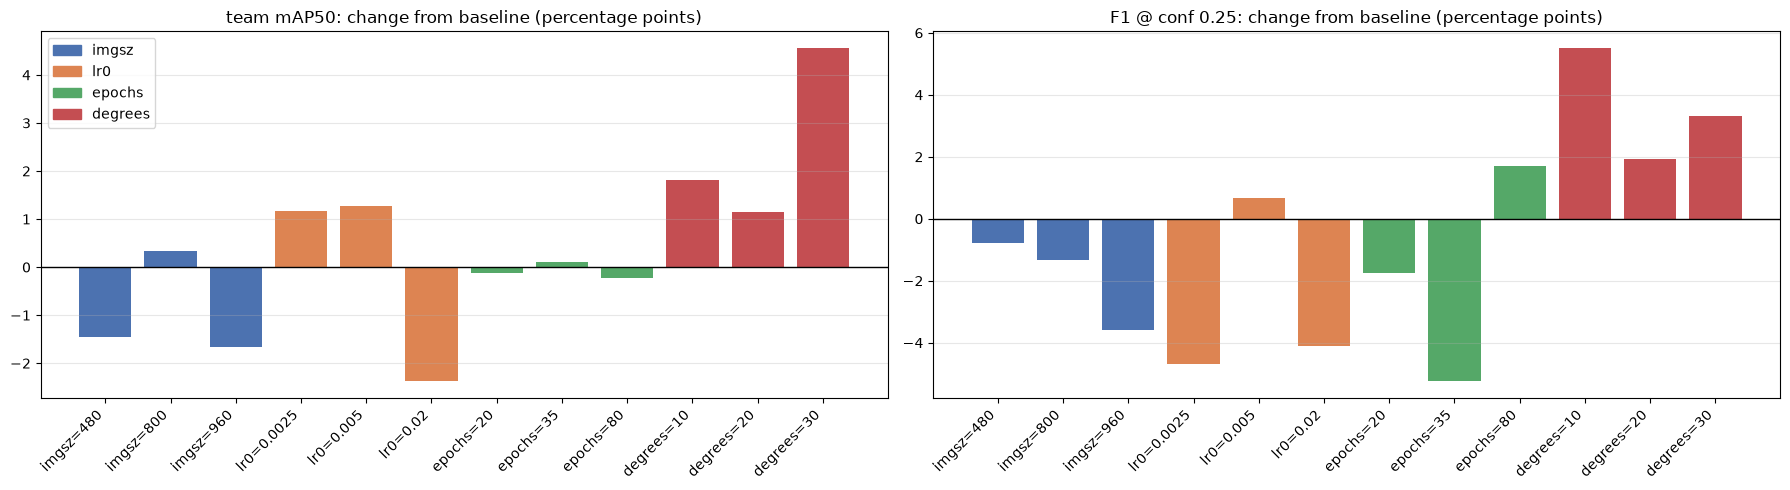

In [6]:
order = [r for r in group.index if r != "baseline"]
colors = {"imgsz": "#4C72B0", "lr0": "#DD8452", "epochs": "#55A868", "degrees": "#C44E52"}
fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharey=False)
for ax, col in zip(axes, ["team mAP50", "F1 @ conf 0.25"]):
    ax.bar(range(len(order)), delta.loc[order, col] * 100,
           color=[colors[group.loc[r, "hyperparameter"]] for r in order])
    ax.axhline(0, color="black", lw=1)
    ax.set_xticks(range(len(order)), order, rotation=45, ha="right")
    ax.set_title(f"{col}: change from baseline (percentage points)"); ax.grid(axis="y", alpha=0.3)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
axes[0].legend(handles, colors.keys())
plt.tight_layout()
fig.savefig(RES / "tuning_group_comparison.png", dpi=110, bbox_inches="tight")
plt.show()

## 3. Combining the winners

Train one model with the best value of every hyperparameter that beat the baseline in section 2 on team mAP50 **and** F1 @ conf 0.25, with everything else at the baseline values. Two hyperparameters qualify:

| Hyperparameter | Value | Δ team mAP50 | Δ F1 @ 0.25 | Why this value |
|---|---|---|---|---|
| `degrees` | 10 | +0.018 | +0.055 | all three angles beat the baseline on both; ±10° has the best F1 and the only gain outside the noise |
| `lr0` | 0.005 | +0.013 | +0.006 | the only learning rate that beat the baseline on both |

`imgsz` 800 (F1 −0.014) and every `epochs` value (mAP50 ≤ +0.001) don't qualify, so they stay at the baseline (640, 50).

**Question:** do the two gains add up? Rotation changes *what* the model sees (tilted hands); a lower learning rate changes *how far* it moves from the COCO weights, so they could combine. A lower learning rate also learns the rotated images more slowly, though, so the combination could also land between the two. The combined model is compared against the baseline and against `degrees=10` alone.

In [7]:
COMBINED = {"degrees": 10, "lr0": 0.005}
weights, out = ROOT / "models" / "combined_best.pt", RES / "combined"
hp = {**BASELINE, **COMBINED}
if not COMBINED:
    print("COMBINED is empty: fill it in from section 2, then re-run this cell. Skipping the combined model.")
elif weights.exists():
    print("combined: already trained ->", weights.name)
else:
    model = YOLO("yolov8s.pt")
    model.train(**hp, project=str(ROOT / "runs"), name="combined", exist_ok=True)
    run = Path(model.trainer.save_dir)
    out.mkdir(parents=True, exist_ok=True)
    shutil.copy2(run / "weights" / "best.pt", weights)
    for f in ["results.csv", "results.png", "args.yaml", "train_batch0.jpg"]:
        if (run / f).exists():
            shutil.copy2(run / f, out / f)
    (out / "metrics.json").write_text(json.dumps(
        {"model": "yolov8s.pt (COCO-pretrained) fine-tuned", "changed": COMBINED, "hyperparameters": hp,
         **train_info(run / "results.csv")}, indent=2))
    del model; torch.cuda.empty_cache()

if COMBINED:
    evaluate(weights, hp["imgsz"], out)
    ea = error_analysis(weights, hp["imgsz"], out)
    print("combined:", {k: ea["summary"][k] for k in ["hands", "correct", "precision", "recall", "F1", "accuracy"]})

New https://pypi.org/project/ultralytics/8.4.208 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=10, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, 

In [8]:
# baseline, the best value of each hyperparameter (by team mAP50), degrees=10 (best F1), and the combined model
keep = list(dict.fromkeys(list(best_per_param.values) + ["degrees=10"]))
final = pd.DataFrame({"baseline": summary_row(RES / "baseline"),
                      **{r: summary_row(dirs[r]) for r in keep}}).T
if COMBINED:
    final.loc["combined"] = pd.Series(summary_row(out))
    dirs["combined"] = out
final[metric_cols] = final[metric_cols].astype(float)
display(final[["epochs_run", "best_epoch", "train_minutes"] + metric_cols].round(3))
pd.DataFrame({r: paired_bootstrap(dirs[r]) for r in final.index if r != "baseline"}).T

,epochs_run,best_epoch,train_minutes,val mAP50,val mAP50-95,team P,team R,team F1,team mAP50,team mAP50-95,team fist mAP50,small-hand recall,P @ conf 0.25,R @ conf 0.25,F1 @ conf 0.25,accuracy @ conf 0.25
baseline,50.0,41.0,15.3,0.990,0.748,0.894,0.775,0.830,0.845,0.418,0.625,0.562,0.838,0.805,0.821,0.697
imgsz=800,50.0,38.0,17.0,0.994,0.756,0.894,0.765,0.825,0.848,0.429,0.642,0.625,0.810,0.805,0.808,0.678
lr0=0.005,47.0,32.0,226.5,0.994,0.756,0.873,0.815,0.843,0.858,0.425,0.669,0.625,0.812,0.844,0.828,0.706
epochs=35,35.0,30.0,5.9,0.994,0.740,0.870,0.729,0.793,0.846,0.432,0.630,0.500,0.771,0.766,0.769,0.624
degrees=30,50.0,45.0,8.2,0.989,0.724,0.914,0.833,0.872,0.890,0.475,0.739,0.625,0.852,0.857,0.854,0.746
degrees=10,50.0,49.0,8.7,0.993,0.740,0.925,0.828,0.874,0.863,0.436,0.677,0.625,0.903,0.851,0.876,0.780
combined,50.0,38.0,8.4,0.995,0.748,0.927,0.806,0.863,0.870,0.452,0.729,0.625,0.854,0.838,0.846,0.733


,F1 change [95% CI],accuracy change [95% CI],share of samples better
imgsz=800,"-0.014 [-0.058, +0.032]","-0.020 [-0.081, +0.046]",0.26
lr0=0.005,"+0.006 [-0.037, +0.051]","+0.009 [-0.054, +0.072]",0.6
epochs=35,"-0.053 [-0.107, -0.000]","-0.073 [-0.146, -0.000]",0.02
degrees=30,"+0.032 [-0.018, +0.087]","+0.048 [-0.028, +0.127]",0.89
degrees=10,"+0.055 [+0.014, +0.102]","+0.082 [+0.021, +0.152]",1.0
combined,"+0.025 [-0.025, +0.079]","+0.036 [-0.037, +0.115]",0.82


## 4. Final model: correct and incorrect examples
Green boxes are our labels, red boxes the model's predictions at conf 0.25 (from `error_analysis()`).

final model: degrees=10 -> results\degrees_10


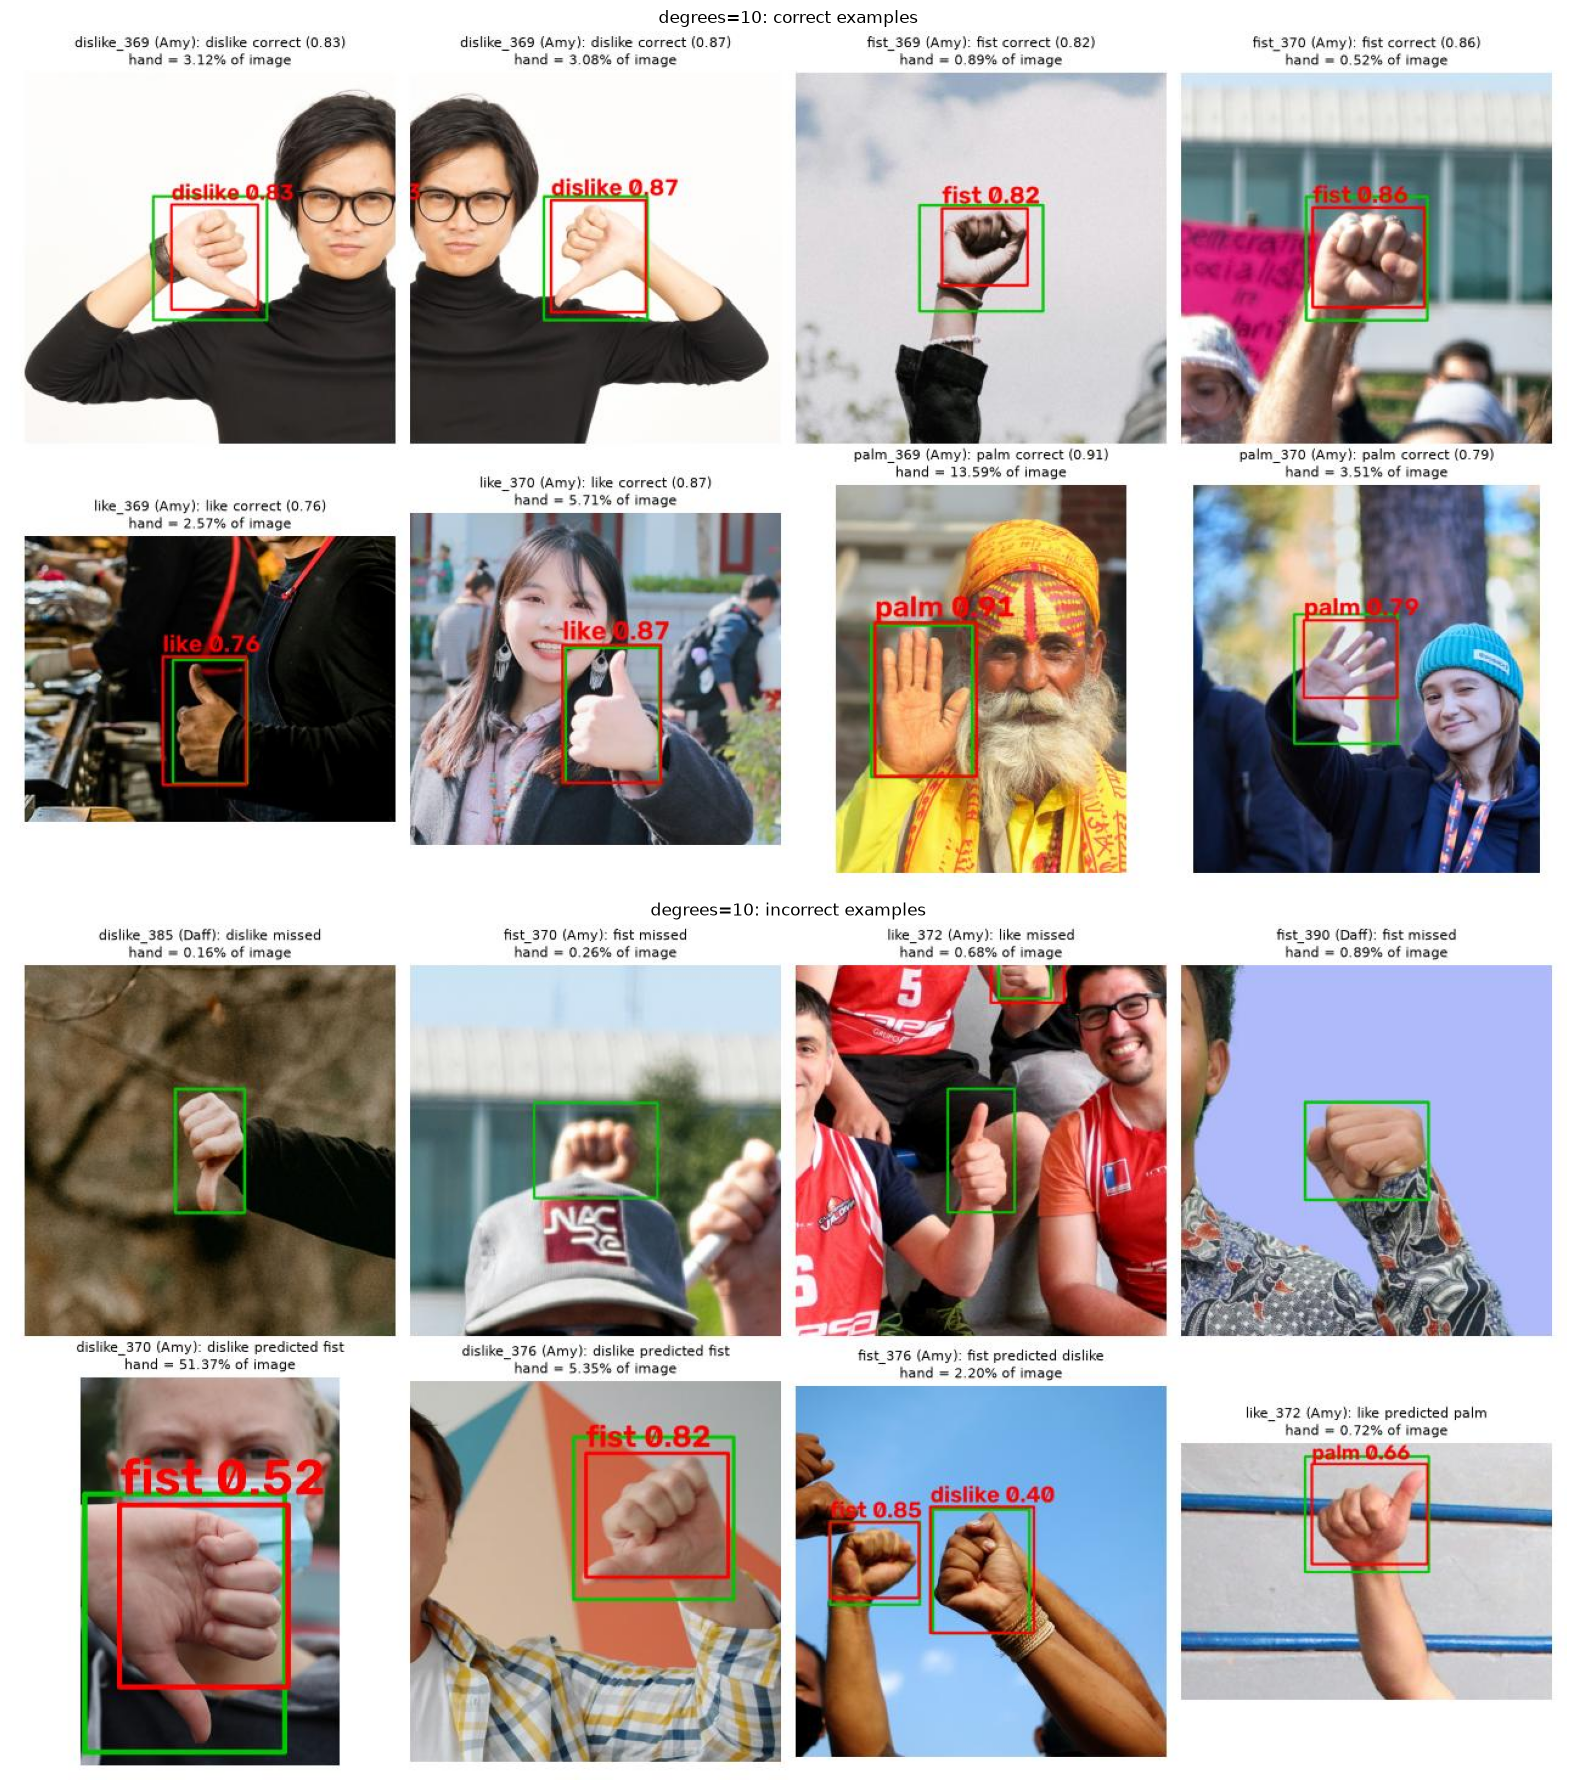

In [9]:
FINAL = final.drop("baseline")["F1 @ conf 0.25"].idxmax()
print("final model:", FINAL, "->", dirs[FINAL].relative_to(ROOT))
fig, axes = plt.subplots(2, 1, figsize=(16, 18))
for ax, f, title in zip(axes, ["correct_cases.jpg", "failure_cases.jpg"], ["correct", "incorrect"]):
    ax.imshow(plt.imread(dirs[FINAL] / f)); ax.set_title(f"{FINAL}: {title} examples"); ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Discussion and final choice
_Filled in after the runs._